In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")     

In [2]:
# loading the Data Sets
path_1 = "churn-bigml-80.csv"
path_2 = "churn-bigml-20.csv"
df_1 = pd.read_csv(path_1)
df_2 = pd.read_csv(path_2)

In [3]:
df_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   object 
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   object 
 4   Voice mail plan         2666 non-null   object 
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   

In [4]:
df_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   667 non-null    object 
 1   Account length          667 non-null    int64  
 2   Area code               667 non-null    int64  
 3   International plan      667 non-null    object 
 4   Voice mail plan         667 non-null    object 
 5   Number vmail messages   667 non-null    int64  
 6   Total day minutes       667 non-null    float64
 7   Total day calls         667 non-null    int64  
 8   Total day charge        667 non-null    float64
 9   Total eve minutes       667 non-null    float64
 10  Total eve calls         667 non-null    int64  
 11  Total eve charge        667 non-null    float64
 12  Total night minutes     667 non-null    float64
 13  Total night calls       667 non-null    int64  
 14  Total night charge      667 non-null    fl

In [5]:
# Combining The Two Datasets to get one master DataFrame
df = pd.concat([df_1, df_2], ignore_index=True)

In [6]:
# Checking how many rows and columns we now have
print ("Shape Of Combined Datasets")
print(f'{df.shape[0]} rows and {df.shape[1]} columns')
print()

Shape Of Combined Datasets
3333 rows and 20 columns



In [7]:
df.describe()

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,101.064806,437.182418,8.099010,179.775098,100.435644,30.562307,200.980348,100.114311,17.083540,200.872037,100.107711,9.039325,10.237294,4.479448,2.764581,1.562856
std,39.822106,42.371290,13.688365,54.467389,20.069084,9.259435,50.713844,19.922625,4.310668,50.573847,19.568609,2.275873,2.791840,2.461214,0.753773,1.315491
min,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.200000,33.000000,1.040000,0.000000,0.000000,0.000000,0.000000
25%,74.000000,408.000000,0.000000,143.700000,87.000000,24.430000,166.600000,87.000000,14.160000,167.000000,87.000000,7.520000,8.500000,3.000000,2.300000,1.000000
50%,101.000000,415.000000,0.000000,179.400000,101.000000,30.500000,201.400000,100.000000,17.120000,201.200000,100.000000,9.050000,10.300000,4.000000,2.780000,1.000000
75%,127.000000,510.000000,20.000000,216.400000,114.000000,36.790000,235.300000,114.000000,20.000000,235.300000,113.000000,10.590000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,51.000000,350.800000,165.000000,59.640000,363.700000,170.000000,30.910000,395.000000,175.000000,17.770000,20.000000,20.000000,5.400000,9.000000


In [8]:
# Checking for missing Values
print ("Missing values for each column")
print (df.isnull().sum())
print()

Missing values for each column
State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64



In [9]:
# Checking for duplicate rows
print(f'Number of duplicate rows: {df.duplicated().sum()}')
print ()

Number of duplicate rows: 0



In [10]:
# checking the data types
print ("Columns names and their data types")
print(df.dtypes)

Columns names and their data types
State                      object
Account length              int64
Area code                   int64
International plan         object
Voice mail plan            object
Number vmail messages       int64
Total day minutes         float64
Total day calls             int64
Total day charge          float64
Total eve minutes         float64
Total eve calls             int64
Total eve charge          float64
Total night minutes       float64
Total night calls           int64
Total night charge        float64
Total intl minutes        float64
Total intl calls            int64
Total intl charge         float64
Customer service calls      int64
Churn                        bool
dtype: object


### Data Cleaning Step 1 - encoding Binary and categorical columns


In [11]:
# converting Churn(True/False) to 1/0
df['Churn'] = df['Churn'].astype(int)


In [12]:
# converting Yes/No Columns to 1/0
binary_columns = ['International plan', 'Voice mail plan']
df[binary_columns] = df[binary_columns].replace({'Yes': 1, 'No': 0})


In [13]:
# Convertimg Area  code to string since it's a categorical label and not a number
df['Area code'] = df['Area code'].astype(str)

In [14]:
# Confirming the changes worked
print("Data types after encoding")
print(df[['Churn', 'International plan', 'Voice mail plan', 'Area code']].dtypes)

Data types after encoding
Churn                  int64
International plan     int64
Voice mail plan        int64
Area code             object
dtype: object


In [15]:
print("value count for the target variable Churn")
print(df['Churn'].value_counts())

value count for the target variable Churn
Churn
0    2850
1     483
Name: count, dtype: int64


###  Cleaning Step 2 - One-Hot Encode State and Area Code

In [16]:
# Identifying the categorical columns
df_encoded = pd.get_dummies(df, columns=['State', 'Area code'], drop_first=True)

In [17]:
print (f"Shape before encoding:{df.shape}")
print (f"Shape after encoding:{df_encoded.shape}")
print()

Shape before encoding:(3333, 20)
Shape after encoding:(3333, 70)



In [18]:
# looking at a sample of the new columns
print ("Sample of the new encoded Column")
print (df_encoded.filter(like="State").head())

Sample of the new encoded Column
   State_AL  State_AR  State_AZ  State_CA  State_CO  State_CT  State_DC  \
0     False     False     False     False     False     False     False   
1     False     False     False     False     False     False     False   
2     False     False     False     False     False     False     False   
3     False     False     False     False     False     False     False   
4     False     False     False     False     False     False     False   

   State_DE  State_FL  State_GA  ...  State_SD  State_TN  State_TX  State_UT  \
0     False     False     False  ...     False     False     False     False   
1     False     False     False  ...     False     False     False     False   
2     False     False     False  ...     False     False     False     False   
3     False     False     False  ...     False     False     False     False   
4     False     False     False  ...     False     False     False     False   

   State_VA  State_VT  State_WA  St

In [19]:
# Converting all boolean columns to integers
bools_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bools_cols] = df_encoded[bools_cols].astype(int)

### Detecting and Handling Outliers

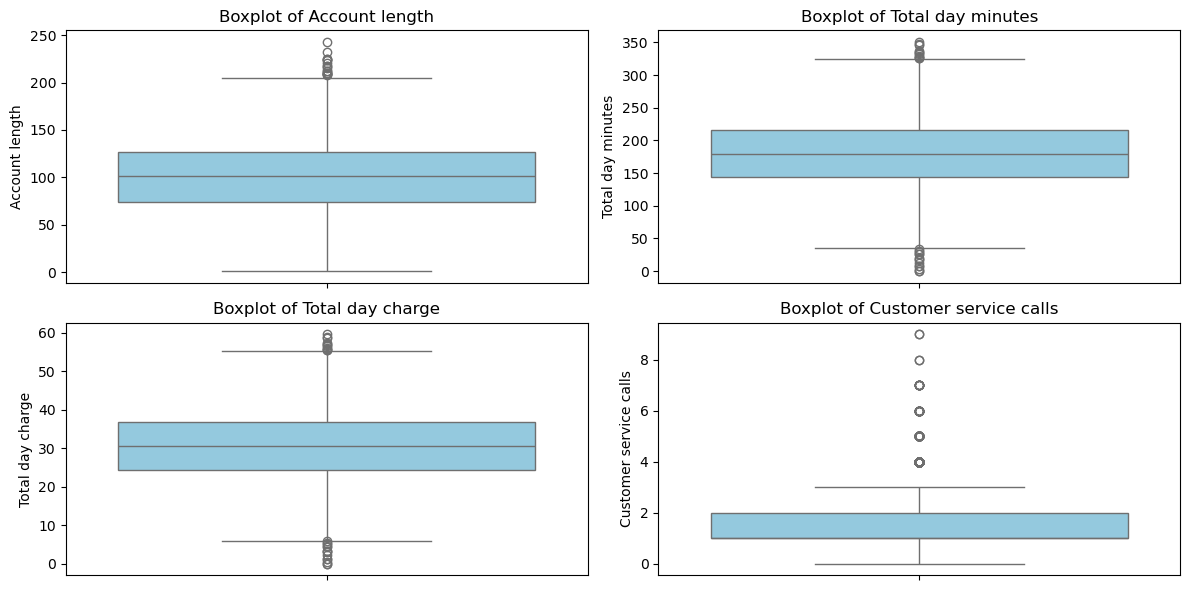

In [20]:
# visualizing outliers using Boxplotsfor a few Key Numeric columns, making use of the original unscaled data
cols_to_check = ['Account length', 'Total day minutes', 'Total day charge', 'Customer service calls']

plt.figure(figsize=(12, 6))
for i, col in enumerate(cols_to_check, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')

    
plt.tight_layout()
plt.show()

In [21]:
# Capping the outliers using the IQR method
continuous_cols = [col for col in df_encoded.columns if 'State' not in col and 'Area code' not in col and col not in ['Churn', 'International plan', 'Voice mail plan']]
skip_cap = ['Customer service calls']

for col in continuous_cols:
    if col in skip_cap:
        print(f"Skipped (genuine signal): {col}")
        continue

    
    Q1 = df_encoded[col].quantile(0.25)
    Q3 = df_encoded[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    # capping the values
    n_capped = ((df_encoded[col] < lower_bound) | (df_encoded[col] > upper_bound)).sum()
    df_encoded[col] = df_encoded[col].clip(lower=lower_bound, upper=upper_bound)

    print(f"{col}: {n_capped} values capped")

Account length: 18 values capped
Number vmail messages: 1 values capped
Total day minutes: 25 values capped
Total day calls: 23 values capped
Total day charge: 25 values capped
Total eve minutes: 24 values capped
Total eve calls: 20 values capped
Total eve charge: 24 values capped
Total night minutes: 30 values capped
Total night calls: 22 values capped
Total night charge: 30 values capped
Total intl minutes: 46 values capped
Total intl calls: 78 values capped
Total intl charge: 49 values capped
Skipped (genuine signal): Customer service calls


In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
scaler = StandardScaler()

In [24]:
# Selecting continuous numeric columns only — excluding the target (Churn)
# and the one-hot dummy columns (State_*, Area code_*), which should stay 0/1
dummy_cols = [c for c in df_encoded.columns if c.startswith(('State_', 'Area code_'))]
binary_cols = ['International plan', 'Voice mail plan']
numeric_cols = df_encoded.select_dtypes(include=['int64', 'float64']).columns.drop('Churn')
scale_cols = [c for c in numeric_cols if c not in dummy_cols + binary_cols]

df_encoded[scale_cols] = scaler.fit_transform(df_encoded[scale_cols])

In [25]:
# Final Data check
print (" FINAL DATA CHECK")
print (f'Total rows: {df_encoded.shape[0]}')
print (f'Total columns: {df_encoded.shape[1]}')

print("Any Missing Values?")
print (df_encoded.isnull().sum().sum())
print()

print ("Any remaining text or boolean columns?")
text_cols = df_encoded.select_dtypes(include=['object', 'bool']).columns.tolist()
print(text_cols if len(text_cols) > 0 else "None, All Columns Are Numeric")
print()


 FINAL DATA CHECK
Total rows: 3333
Total columns: 70
Any Missing Values?
0

Any remaining text or boolean columns?
None, All Columns Are Numeric



In [26]:
df_encoded.to_csv('churn_cleaned.csv', index=False)
print("\nCleaned data saved Successfully as 'churn_cleaned.csv'!")


Cleaned data saved Successfully as 'churn_cleaned.csv'!


In [27]:
df_encoded.describe()

,Account length,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,...,State_TX,State_UT,State_VA,State_VT,State_WA,State_WI,State_WV,State_WY,Area code_415,Area code_510
count,3.333000e+03,3333.000000,3333.000000,3.333000e+03,3.333000e+03,3.333000e+03,3.333000e+03,3.333000e+03,3.333000e+03,3.333000e+03,...,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,1.001965e-16,0.096910,0.276628,-3.943907e-17,2.046568e-16,-1.209820e-16,-2.472936e-16,-3.666767e-16,6.288932e-17,-2.131841e-17,...,0.021602,0.021602,0.023102,0.021902,0.019802,0.023402,0.031803,0.023102,0.496550,0.252025
std,1.000150e+00,0.295879,0.447398,1.000150e+00,1.000150e+00,1.000150e+00,1.000150e+00,1.000150e+00,1.000150e+00,1.000150e+00,...,0.145402,0.145402,0.150251,0.146386,0.139340,0.151200,0.175502,0.150251,0.500063,0.434241
min,-2.522904e+00,0.000000,0.000000,-5.917781e-01,-2.681109e+00,-2.717600e+00,-2.681225e+00,-2.727707e+00,-2.714881e+00,-2.728151e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-6.812450e-01,0.000000,0.000000,-5.917781e-01,-6.670381e-01,-6.784029e-01,-6.669893e-01,-6.828129e-01,-6.648298e-01,-6.830911e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-8.326143e-05,0.000000,0.000000,-5.917781e-01,-7.686098e-03,2.650466e-02,-7.528063e-03,7.748156e-03,-6.788627e-03,7.933806e-03,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,6.558502e-01,0.000000,1.000000,8.696352e-01,6.756760e-01,6.810617e-01,6.758346e-01,6.804499e-01,7.018711e-01,6.802823e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,2.661493e+00,1.000000,1.000000,3.061755e+00,2.689747e+00,2.720259e+00,2.690070e+00,2.725344e+00,2.751922e+00,2.725342e+00,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Findings and Conclusion

**Objective:** Prepare the telecom customer churn data for machine learning by combining the two files, cleaning and encoding the features, handling outliers and scaling the numeric columns.

**Data:** The two files (churn-bigml-80 with 2,666 rows and churn-bigml-20 with 667 rows) were combined into one dataset of 3,333 customers and 20 columns. There were no missing values and no duplicate rows. The target, Churn, is imbalanced: 2,850 customers stayed (85.5%) and 483 churned (14.5%).

**Cleaning and preparation steps**
1. **Binary encoding:** Churn (True/False) was converted to 1/0, and International plan and Voice mail plan (Yes/No) were converted to 1/0.
2. **Categorical encoding:** Area code was treated as a label rather than a number and, together with State, was one-hot encoded with the first category dropped. This took the dataset from 20 to 70 columns, and all boolean columns were then converted to integers.
3. **Outlier handling:** Boxplots were used to inspect outliers, and values outside 1.5 x IQR were capped (not removed) in 14 numeric columns, 415 values in total. The most affected columns were Total intl calls (78 values), Total intl charge (49), Total intl minutes (46), and Total night minutes and Total night charge (30 each). Account length had 18 capped values and Number vmail messages only 1. Customer service calls was deliberately left uncapped because unusually high call counts may be a genuine churn signal.
4. **Scaling:** StandardScaler was applied to the continuous numeric columns only. The binary plan columns and the State and Area code dummies were left as 0/1. After scaling, the continuous columns have a mean of about 0 and a standard deviation of about 1.
5. **Final check:** The cleaned dataset has 3,333 rows and 70 columns, with 0 missing values and no remaining text or boolean columns. It was saved as `churn_cleaned.csv`.

**Key findings**
1. **The raw data was already clean.** No missing values or duplicates needed handling, so the main work was encoding and outlier treatment.
2. **Outliers were mild and mostly in usage columns.** Capping affected only 415 values in total across a dataset of 3,333 rows and 14 columns, and capping kept every customer in the data.
3. **Churn is imbalanced (14.5% churners).** Accuracy alone would be misleading on this target, since predicting "no churn" for everyone would already be about 85.5% correct. Later modelling should use stratified splits, class weighting or resampling, and metrics such as recall, precision, F1 or ROC-AUC.
4. **One-hot encoding expanded the feature space.** State and Area code account for 52 of the 70 columns, so the final dataset has many sparse columns relative to the 18 other features.

**Limitations**
- **Possible data leakage.** Outlier capping and scaling were done on the full dataset before any train/test split, so the test data influenced the capping bounds and scaling statistics. In the modelling stage, these steps should be fitted on the training set only (for example inside a pipeline).
- **Redundant features not checked.** This notebook did not examine correlations between features. Minutes and charge columns for the same period may carry nearly the same information.
- **No modelling yet.** The notebook prepares the data but does not show which features actually drive churn.

**Next steps:** split the data with stratification, move scaling and capping into a training-only pipeline, check feature correlations, and train and compare classification models (for example Logistic Regression and Random Forest) using recall, precision and F1 for the churn class.